In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_selection import mutual_info_regression

方差 = 波动性 = 不确定性  
特征今天的波动，能否预测市场明天的波动？  
希望能找到预测目标变量未来波动性的特征

注意点：  
先计算每个特征的滚动方差，然后再其进行标准化处理  
目标变量的方差是衡量的基准，需要保持其原有的、真实的含义，所以不进行标准化处理  

如果用StandardScalar在整个训练集的特征列进行标准化（`fit_transform`）会引入未来信息、造成数据泄露  
所以在这里我们使用滚动标准化，这和计算方差的时候使用的滚动方差思想一致

In [5]:
clean_df = pd.read_csv('../EDA/clean_train.csv')
clean_df.head()

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V2,V3,V4,V5,V6,V7,V8,forward_returns,risk_free_rate,target
0,1006,0,0,0,1,0,-1,0,0,0,...,0.986772,0.970899,0.986111,0.0,0.000661,0.0,0.000661,-0.000669,0.000121,-0.001100
1,1007,0,0,0,1,0,-1,0,0,0,...,0.984788,0.972884,0.984788,0.0,0.000661,0.0,0.000661,0.005348,0.000121,0.004917
2,1008,0,0,0,1,0,-1,0,0,0,...,0.982143,0.834656,0.983466,0.0,0.000661,0.0,0.000661,0.001996,0.000121,0.001565
3,1009,0,0,0,1,0,-1,0,0,0,...,0.980159,0.928571,0.979497,0.0,0.000661,0.0,0.000661,-0.001327,0.000121,-0.001758
4,1010,0,0,0,1,0,0,0,1,0,...,1.000000,0.997354,1.000000,0.0,0.000661,0.0,0.000661,-0.003987,0.000119,-0.004415


In [3]:
M_cols = [c for c in clean_df.columns if c.startswith('M')]
E_cols = [c for c in clean_df.columns if c.startswith('E')]
I_cols = [c for c in clean_df.columns if c.startswith('I')]
P_cols = [c for c in clean_df.columns if c.startswith('P')]
V_cols = [c for c in clean_df.columns if c.startswith('V')]
S_cols = [c for c in clean_df.columns if c.startswith('S')]

groups = {
    "Market Dynamics (M*)": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
}

features = M_cols + E_cols + I_cols + P_cols + V_cols + S_cols

print('We have a total of {} features excluding date_id, binary features, forward_returns, risk_free_rate and the target variable.'.format(len(features)))

We have a total of 76 features excluding date_id, binary features, forward_returns, risk_free_rate and the target variable.


In [4]:
WINDOW = 63  # 一个季度的滚动窗口

# 计算所选特征的滚动方差（不含 date_id, binary features, forward_returns, risk_free_rate and the target variable）
feature_var = clean_df[features].rolling(window=WINDOW).var()

# 单独计算target的滚动方差
target_var = clean_df['target'].rolling(WINDOW).var().rename('target_var')

**下面对所选特征进行滚动标准化处理**

In [5]:
feature_var_mean = feature_var.rolling(window=WINDOW).mean()
feature_var_std = feature_var.rolling(window=WINDOW).std()
standardized_feature_var = (feature_var - feature_var_mean) / (feature_var_std + 1e-9)  # 防止分母为 0 导致结果出现 inf 值
standardized_feature_var

,M10,M11,M12,M15,M16,M17,M18,M2,M3,M4,...,S1,S10,S11,S2,S4,S5,S6,S7,S8,S9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7979,-0.875764,-1.250115,-1.271350,0.818176,-0.868369,-1.405716,-1.119862,-0.828133,-1.339562,-0.891293,...,-0.234117,-0.021386,-2.409830,-0.955001,-2.180586,-3.005118,2.715889,-1.681571,-1.400975,-0.358954
7980,-0.786222,-1.218511,-1.220282,0.742158,-0.807583,-1.418257,-1.097946,-0.835381,-1.249662,-0.874000,...,-0.286089,-0.153348,-2.591376,-0.917541,-2.530775,-3.039289,2.507387,-1.931781,-1.380896,-0.610072
7981,-0.698848,-1.182407,-1.175037,0.666195,-0.777038,-1.441056,-1.077975,-0.815976,-1.213744,-0.855318,...,-0.308948,-0.547979,-3.063992,-0.874135,-3.004086,-2.911603,2.402051,-2.147507,-1.354981,-1.291783
7982,-0.612996,-1.139898,-1.132030,0.578143,-0.742558,-1.461566,-1.059815,-0.820026,-1.178237,-0.832429,...,-0.328634,-0.112665,-2.112904,-0.833460,-2.027819,-2.947456,2.325954,-2.327408,-1.328360,-1.325364


In [6]:
# 检查 standardized_feature_var 中每列的 NaN 总数
nan_counts = standardized_feature_var.isna().sum()

print('Number of NaNs in each feature of standardized_feature_var:')
print(nan_counts[nan_counts > 0])

# 检查是否有 inf
inf_counts = np.isinf(standardized_feature_var).sum()
print('\nNumber of Infs in each feature of standardized_feature_var:')
print(inf_counts[inf_counts > 0])

Number of NaNs in each feature of standardized_feature_var:
M10    124
M11    124
M12    124
M15    124
M16    124
      ... 
S5     124
S6     124
S7     124
S8     124
S9     124
Length: 76, dtype: int64

Number of Infs in each feature of standardized_feature_var:
Series([], dtype: int64)


注意这里发现每个特征在进行滚动标准化之后会出现 124 个 NaNs  
这是应该的，因为在计算滚动方差的时候一开始有 62 个 NaNs，然后接着计算滚动平均值的时候又出现了 62 个 NaNs

**先通过计算 Sample Pearson Correlation Coefficient 来找到能预测目标变量未来波动性的特征**

In [7]:
vol_pred_score = standardized_feature_var.corrwith(target_var)
vol_pred_score = vol_pred_score.sort_values(ascending=False)

print('Linear volatility predictive score of selected features and the target:', '\n')
print(vol_pred_score)

Linear volatility predictive score of selected features and the target: 

M4     0.176381
P7     0.176318
M2     0.169254
P8     0.139784
S5     0.131669
         ...   
V12   -0.076397
P4    -0.094815
P5    -0.109169
P1    -0.109543
P12   -0.122763
Length: 76, dtype: float64


In [8]:
print(vol_pred_score[(vol_pred_score.isna())])
print(vol_pred_score[np.isinf(vol_pred_score)])

Series([], dtype: float64)
Series([], dtype: float64)


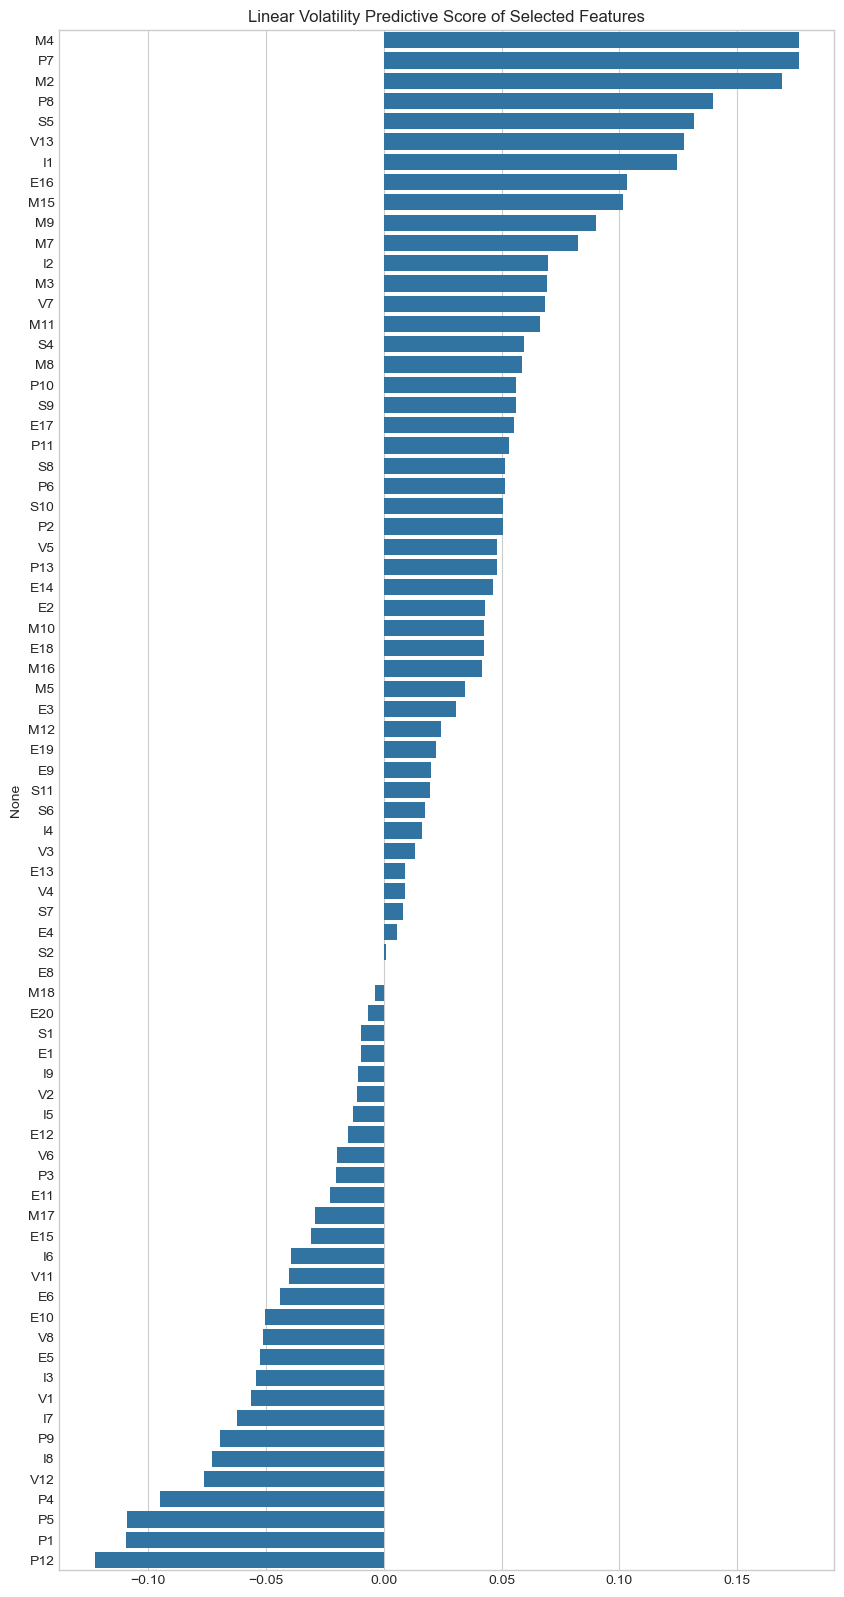

In [9]:
plt.figure(figsize=(10, 20))
sns.barplot(y=vol_pred_score.index, x=vol_pred_score.values)
plt.title("Linear Volatility Predictive Score of Selected Features")
plt.savefig("linear_volatility_predictive_score.png", dpi=300)
plt.show()

**再计算 Mutual Information 进行确认**

In [10]:
print('Are all selected features of float data type (continuous features)?')
if (clean_df[features].dtypes == 'float').all() == True:
    print('Yes')

Are all selected features of float data type (continuous features)?
Yes


In [13]:
def make_mi_scores(X, y):
    mi_scores = mutual_info_regression(X, y, discrete_features=False)
    mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
    return mi_scores

In [14]:
# 因为 MI 如果处理 NaNs，所以在计算之前需要先删除任何包含 NaNs 的行
temp_df = standardized_feature_var.copy()
temp_df['target_var'] = target_var
temp_df.dropna(inplace=True)

# 重新分离出特征方差（X）和 target 方差（y）
X = temp_df.drop(columns=['target_var'])
y = temp_df['target_var']

# 计算互信息
mi_scores = make_mi_scores(X, y)
print('Non-linear volatility predictive score of selected features and the target:\n')
print(mi_scores)

Non-linear volatility predictive score of selected features and the target:

E1     0.392260
V13    0.339938
P6     0.339483
S5     0.314913
P5     0.297938
         ...   
V11    0.145060
E5     0.139245
M16    0.135143
P3     0.115010
P4     0.111540
Length: 76, dtype: float64


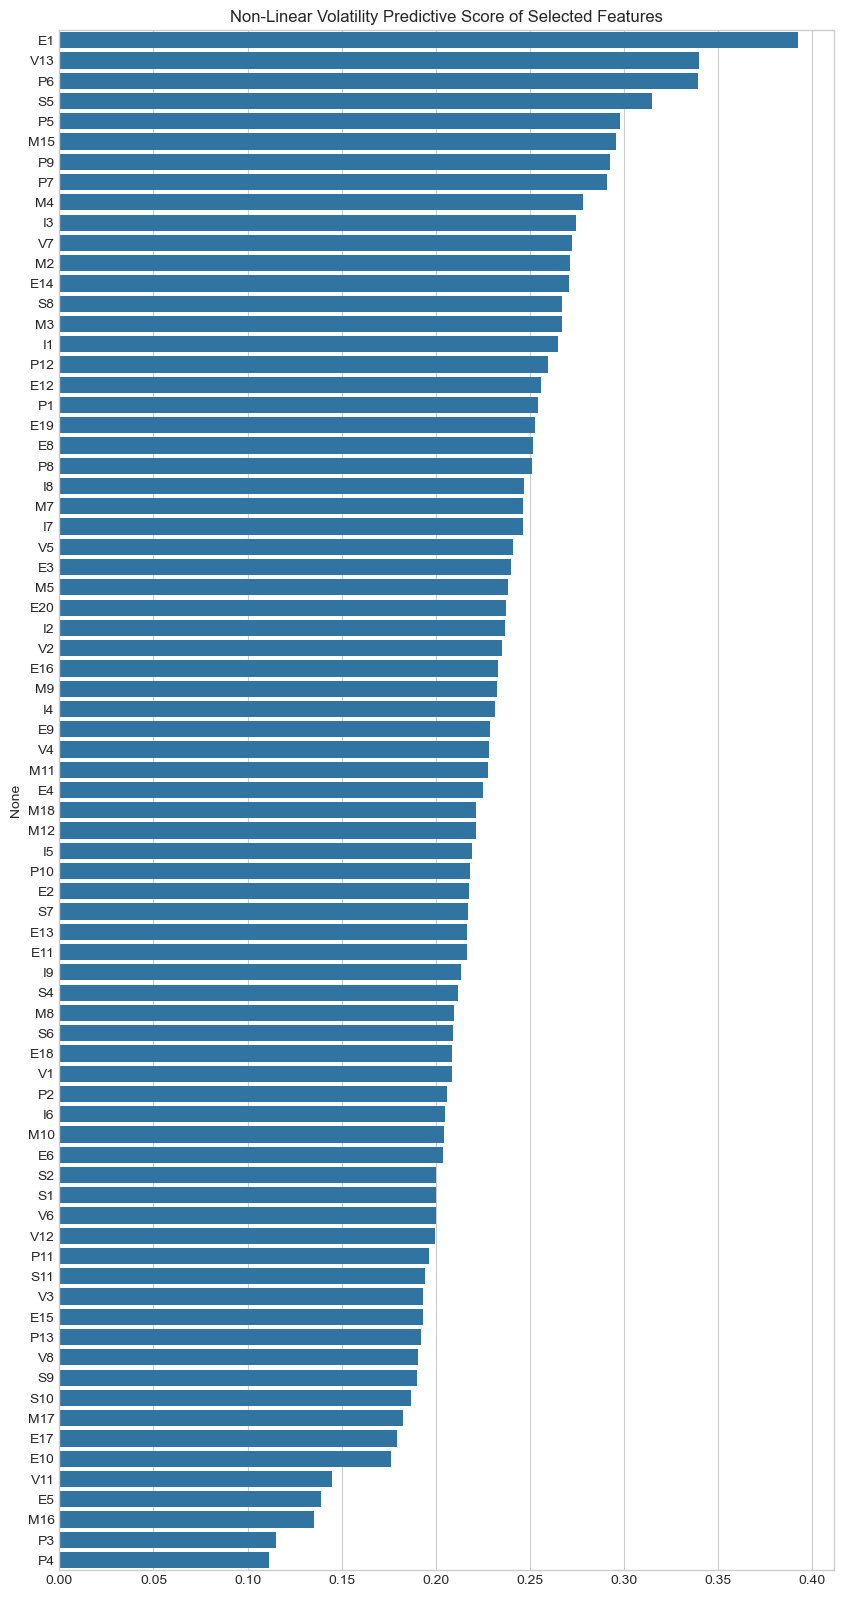

In [15]:
plt.figure(figsize=(10, 20))
sns.barplot(y=mi_scores.index, x=mi_scores.values)
plt.title("Non-Linear Volatility Predictive Score of Selected Features")
plt.savefig("non-linear_volatility_predictive_score.png", dpi=300)
plt.show()

**通过 MI 能直接告诉我们哪些特征重要，然后结合 Pearson 告诉我们这些特征是如何重要的（提供方向性）**

In [38]:
comparison_df = pd.DataFrame({
    'pearson_corr': vol_pred_score,
    'mi_scores': mi_scores
})

mi_threshold = comparison_df['mi_scores'].mean()

high_mi_features = comparison_df[comparison_df['mi_scores'] >= mi_threshold].index
low_mi_features = comparison_df[comparison_df['mi_scores'] < mi_threshold].index

pos_pearson_features = comparison_df[comparison_df['pearson_corr'] >= 0].index
neg_pearson_features = comparison_df[comparison_df['pearson_corr'] < 0].index

# Quadrant 1: High MI, Positive Pearson
q1_all_stars = list(set(high_mi_features) & set(pos_pearson_features))

# Quadrant 2: High MI, Negative Pearson
q2_hidden_gems = list(set(high_mi_features) & set(neg_pearson_features))

# Quadrant 3: Low MI, Positive Pearson
q3_linear_only = list(set(low_mi_features) & set(pos_pearson_features))

# Quadrant 4: Low MI, Negative Pearson
q4_noise = list(set(low_mi_features) & set(neg_pearson_features))

print('\nQuadrant 1: All-Stars ({} features)'.format(len(q1_all_stars)))
print(q1_all_stars)

print('\nQuadrant 2: Hidden Gems ({} features)'.format(len(q2_hidden_gems)))
print(q2_hidden_gems)

print('\nQuadrant 3: Purely Linear Signals ({} features)'.format(len(q3_linear_only)))
print(q3_linear_only)

print('\nQuadrant 4: Noise & Weak Signals ({} features)'.format(len(q4_noise)))
print(q4_noise)


Quadrant 1: All-Stars (24 features)
['I4', 'M3', 'E3', 'M2', 'M7', 'S8', 'M5', 'E8', 'I1', 'I2', 'P6', 'V7', 'M15', 'P7', 'S5', 'P8', 'V5', 'M9', 'E19', 'E14', 'M4', 'E9', 'V13', 'E16']

Quadrant 2: Hidden Gems (11 features)
['V2', 'E20', 'P12', 'E12', 'E1', 'I3', 'P5', 'P1', 'I7', 'I8', 'P9']

Quadrant 3: Purely Linear Signals (23 features)
['S4', 'S11', 'V3', 'P11', 'M8', 'E4', 'M10', 'P2', 'V4', 'E18', 'E13', 'M12', 'M11', 'M16', 'S7', 'E2', 'S6', 'P10', 'S9', 'S2', 'S10', 'P13', 'E17']

Quadrant 4: Noise & Weak Signals (18 features)
['I6', 'M17', 'E15', 'P4', 'V12', 'V6', 'V11', 'V1', 'E6', 'E5', 'E11', 'E10', 'S1', 'P3', 'I9', 'M18', 'I5', 'V8']
